# ICT4403 Assignment 2 — Next-word text generation
Train Simple RNN, Bidirectional RNN, LSTM, and GRU models on the same text. Run cells in order in VS Code. Install the packages in `requirements.txt` and select that Python environment as the notebook kernel.

On Windows, `import torch` requires the Microsoft Visual C++ Redistributable (x64). If the first code cell reports a missing `shm.dll` dependency, use the installation link and verification command in `README.md`, restart VS Code, and rerun.

## 1. Dataset and preprocessing
Dataset: Lewis Carroll, *Alice's Adventures in Wonderland*, Project Gutenberg eBook 11: https://www.gutenberg.org/ebooks/11 . The code downloads the plain text, removes Project Gutenberg material and the table of contents, then lowercases and tokenizes words plus punctuation.

In [3]:
import copy
import csv
import math
import os
import re
import time
from collections import Counter
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
torch.set_num_threads(min(4, os.cpu_count() or 1))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
data_dir = Path('data')
results_dir = Path('results')
data_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)
print('Device:', device)


Device: cuda


In [4]:
dataset_path = data_dir / 'alice.txt'
dataset_url = 'https://www.gutenberg.org/cache/epub/11/pg11.txt'
if not dataset_path.exists():
    request = Request(dataset_url, headers={'User-Agent': 'Mozilla/5.0'})
    with urlopen(request, timeout=30) as response:
        dataset_path.write_bytes(response.read())

raw_text = dataset_path.read_text(encoding='utf-8-sig')
start_marker = '*** START OF THE PROJECT GUTENBERG EBOOK'
end_marker = '*** END OF THE PROJECT GUTENBERG EBOOK'
assert start_marker in raw_text and end_marker in raw_text, 'Unexpected Gutenberg text format'
book = raw_text.split(start_marker, 1)[1].split('***', 1)[1].split(end_marker, 1)[0]
chapter_matches = list(re.finditer(r'CHAPTER I\.\s*Down the Rabbit-Hole', book))
assert len(chapter_matches) >= 2, 'Could not locate the first chapter after the contents'
book = book[chapter_matches[-1].end():]
book = book.replace('’', "'").replace('‘', "'").lower()
tokens = re.findall(r"[a-z]+(?:'[a-z]+)?|[.!?,;:]", book)
print('Characters:', len(book))
print('Tokens:', len(tokens))
print('Unique tokens:', len(set(tokens)))
print('First 40 tokens:', tokens[:40])

Characters: 143988
Tokens: 31175
Unique tokens: 2634
First 40 tokens: ['alice', 'was', 'beginning', 'to', 'get', 'very', 'tired', 'of', 'sitting', 'by', 'her', 'sister', 'on', 'the', 'bank', ',', 'and', 'of', 'having', 'nothing', 'to', 'do', ':', 'once', 'or', 'twice', 'she', 'had', 'peeped', 'into', 'the', 'book', 'her', 'sister', 'was', 'reading', ',', 'but', 'it', 'had']


## 2. Chronological split and input–target windows
Every example uses the previous 16 tokens to predict the next token. The vocabulary is built from training text only. Splitting before creating windows prevents examples from crossing train/validation/test boundaries. Unknown validation and test words map to `<unk>`.

In [5]:
context_length = 16
train_end = int(0.8 * len(tokens))
validation_end = int(0.9 * len(tokens))
train_words = tokens[:train_end]
validation_words = tokens[train_end:validation_end]
test_words = tokens[validation_end:]
word_counts = Counter(train_words)
vocabulary = ['<unk>'] + sorted(word for word, count in word_counts.items() if count >= 2)
word_to_id = {word: index for index, word in enumerate(vocabulary)}
unknown_id = word_to_id['<unk>']

def encode(words):
    return [word_to_id.get(word, unknown_id) for word in words]

def make_windows(words):
    encoded = encode(words)
    inputs = [encoded[index - context_length:index] for index in range(context_length, len(encoded))]
    targets = encoded[context_length:]
    return TensorDataset(torch.tensor(inputs, dtype=torch.long), torch.tensor(targets, dtype=torch.long))

train_set = make_windows(train_words)
validation_set = make_windows(validation_words)
test_set = make_windows(test_words)
assert all(len(dataset) > 0 for dataset in (train_set, validation_set, test_set))
batch_size = 128
validation_loader = DataLoader(validation_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)
print('Split sizes:', len(train_words), len(validation_words), len(test_words))
print('Vocabulary size:', len(vocabulary))
print('Examples:', len(train_set), len(validation_set), len(test_set))
print('Unknown rates:', {name: round(sum(word not in word_to_id for word in split) / len(split), 4) for name, split in [('train', train_words), ('validation', validation_words), ('test', test_words)]})
print('First input:', [vocabulary[index] for index in train_set[0][0].tolist()])
print('First target:', vocabulary[train_set[0][1].item()])

Split sizes: 24940 3117 3118
Vocabulary size: 1302
Examples: 24924 3101 3102
Unknown rates: {'train': 0.0413, 'validation': 0.0985, 'test': 0.11}
First input: ['alice', 'was', 'beginning', 'to', 'get', 'very', 'tired', 'of', 'sitting', 'by', 'her', 'sister', 'on', 'the', 'bank', ',']
First target: and


## 3. Four recurrent models
Each model receives only the tokens before the target word. For the bidirectional RNN, both directions process the known context window; neither receives the target or later text. Its final forward and backward hidden states are concatenated for prediction.

In [6]:
class NextWordModel(nn.Module):
    def __init__(self, model_kind, vocabulary_size, embedding_size=64, hidden_size=96):
        super().__init__()
        self.model_kind = model_kind
        self.embedding = nn.Embedding(vocabulary_size, embedding_size)
        if model_kind == 'Simple RNN':
            self.recurrent = nn.RNN(embedding_size, hidden_size, batch_first=True)
        elif model_kind == 'Bidirectional RNN':
            self.recurrent = nn.RNN(embedding_size, hidden_size, batch_first=True, bidirectional=True)
        elif model_kind == 'LSTM':
            self.recurrent = nn.LSTM(embedding_size, hidden_size, batch_first=True)
        elif model_kind == 'GRU':
            self.recurrent = nn.GRU(embedding_size, hidden_size, batch_first=True)
        else:
            raise ValueError(f'Unknown model: {model_kind}')
        output_size = hidden_size * (2 if model_kind == 'Bidirectional RNN' else 1)
        self.output = nn.Linear(output_size, vocabulary_size)

    def forward(self, inputs):
        recurrent_result = self.recurrent(self.embedding(inputs))[1]
        hidden = recurrent_result[0] if self.model_kind == 'LSTM' else recurrent_result
        final_state = torch.cat((hidden[-2], hidden[-1]), dim=1) if self.model_kind == 'Bidirectional RNN' else hidden[-1]
        return self.output(final_state)

model_names = ['Simple RNN', 'Bidirectional RNN', 'LSTM', 'GRU']
for name in model_names:
    model = NextWordModel(name, len(vocabulary))
    print(name, 'parameters:', sum(parameter.numel() for parameter in model.parameters()))

Simple RNN parameters: 225174
Bidirectional RNN parameters: 365718
LSTM parameters: 271830
GRU parameters: 256278


## 4. Train and evaluate
All models use Adam, learning rate 0.001, the same batch size and epoch count, and the same shuffled batch order. The best validation-loss weights are restored before one test evaluation. Perplexity is `exp(mean cross-entropy loss)`; accuracy is exact next-word accuracy. Training time includes training and validation passes.

In [7]:
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_count = 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            logits = model(inputs)
            total_loss += nn.functional.cross_entropy(logits, targets, reduction='sum').item()
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_count += targets.numel()
    mean_loss = total_loss / total_count
    return {'loss': mean_loss, 'perplexity': math.exp(mean_loss), 'accuracy': total_correct / total_count}

epochs = 5
models = {}
histories = {}
metrics = []
for name in model_names:
    torch.manual_seed(42)
    model = NextWordModel(name, len(vocabulary)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(42))
    history = {'train_loss': [], 'validation_loss': []}
    best_validation_loss = float('inf')
    best_weights = None
    start_time = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = nn.functional.cross_entropy(model(inputs), targets)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            loss_sum += loss.item() * targets.numel()
        train_loss = loss_sum / len(train_set)
        validation = evaluate(model, validation_loader)
        history['train_loss'].append(train_loss)
        history['validation_loss'].append(validation['loss'])
        if validation['loss'] < best_validation_loss:
            best_validation_loss = validation['loss']
            best_weights = copy.deepcopy(model.state_dict())
        print(f'{name}, epoch {epoch}: train loss={train_loss:.3f}, validation loss={validation["loss"]:.3f}')
    training_seconds = time.perf_counter() - start_time
    model.load_state_dict(best_weights)
    test = evaluate(model, test_loader)
    models[name] = model
    histories[name] = history
    metrics.append({'model': name, 'parameters': sum(parameter.numel() for parameter in model.parameters()), 'validation_loss': best_validation_loss, 'test_loss': test['loss'], 'test_perplexity': test['perplexity'], 'test_accuracy': test['accuracy'], 'training_seconds': training_seconds})
    print(f'{name}: test perplexity={test["perplexity"]:.2f}, accuracy={test["accuracy"]:.2%}, time={training_seconds:.1f}s')

with (results_dir / 'metrics.csv').open('w', newline='', encoding='utf-8') as file:
    writer = csv.DictWriter(file, fieldnames=metrics[0].keys())
    writer.writeheader()
    writer.writerows(metrics)
print('Best validation model:', min(metrics, key=lambda row: row['validation_loss'])['model'])

Simple RNN, epoch 1: train loss=5.662, validation loss=4.871
Simple RNN, epoch 2: train loss=5.007, validation loss=4.631
Simple RNN, epoch 3: train loss=4.715, validation loss=4.472
Simple RNN, epoch 4: train loss=4.495, validation loss=4.390
Simple RNN, epoch 5: train loss=4.317, validation loss=4.318
Simple RNN: test perplexity=78.41, accuracy=21.37%, time=5.1s
Bidirectional RNN, epoch 1: train loss=5.543, validation loss=4.756
Bidirectional RNN, epoch 2: train loss=4.821, validation loss=4.561
Bidirectional RNN, epoch 3: train loss=4.472, validation loss=4.410
Bidirectional RNN, epoch 4: train loss=4.188, validation loss=4.365
Bidirectional RNN, epoch 5: train loss=3.935, validation loss=4.321
Bidirectional RNN: test perplexity=79.61, accuracy=20.83%, time=5.3s
LSTM, epoch 1: train loss=5.703, validation loss=4.980
LSTM, epoch 2: train loss=5.163, validation loss=4.783
LSTM, epoch 3: train loss=4.935, validation loss=4.593
LSTM, epoch 4: train loss=4.749, validation loss=4.493
LSTM

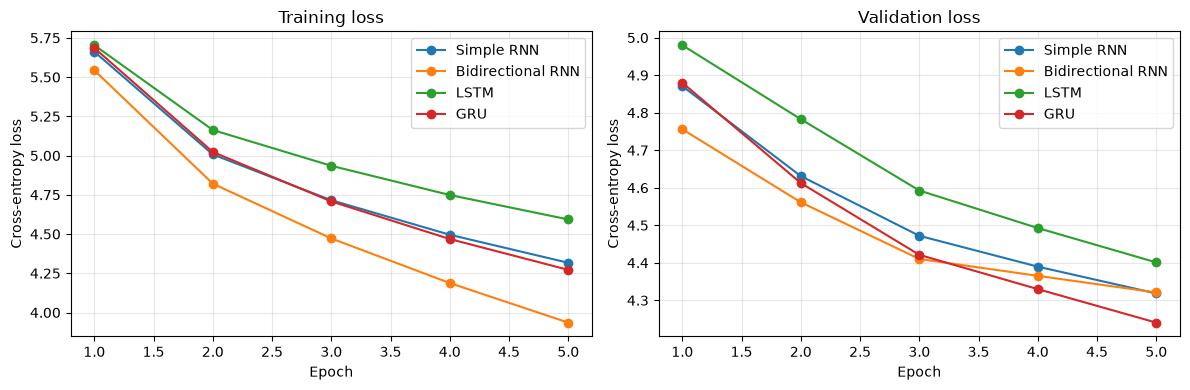

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    axes[0].plot(range(1, epochs + 1), history['train_loss'], marker='o', label=name)
    axes[1].plot(range(1, epochs + 1), history['validation_loss'], marker='o', label=name)
for axis, title in zip(axes, ['Training loss', 'Validation loss']):
    axis.set(title=title, xlabel='Epoch', ylabel='Cross-entropy loss')
    axis.grid(alpha=0.3)
    axis.legend()
fig.tight_layout()
fig.savefig(results_dir / 'training_curves.png', dpi=150)
plt.show()

## 5. Generate from identical seeds at three temperatures
The three seed phrases come from different positions in held-out text. All models receive the same seeds and sample 40 new tokens at temperatures 0.5, 1.0, and 1.5. Lower temperature favors high-probability words; higher temperature gives less likely words more chance. Read the saved examples to judge coherence and contextual consistency yourself.

In [9]:
def readable(words):
    return re.sub(r'\s+([.!?,;:])', r'\1', ' '.join(words))

def generate(model, seed_words, temperature, new_words=40):
    model.eval()
    output_ids = encode(seed_words)
    generated_ids = []
    with torch.no_grad():
        for _ in range(new_words):
            context = torch.tensor([output_ids[-context_length:]], device=device)
            logits = model(context).squeeze(0) / temperature
            logits[unknown_id] = -float('inf')
            next_id = torch.multinomial(torch.softmax(logits, dim=0), 1).item()
            output_ids.append(next_id)
            generated_ids.append(next_id)
    return [vocabulary[index] for index in generated_ids]

seed_offsets = [0, len(test_words) // 3, 2 * len(test_words) // 3]
seeds = [test_words[offset:offset + context_length] for offset in seed_offsets]
temperatures = [0.5, 1.0, 1.5]
sample_rows = []
sample_stats = []
for name in model_names:
    for seed_number, seed in enumerate(seeds, start=1):
        for temperature_index, temperature in enumerate(temperatures):
            torch.manual_seed(1000 + 100 * seed_number + temperature_index)
            generated = generate(models[name], seed, temperature)
            full_text = readable(seed + generated)
            bigrams = list(zip(generated, generated[1:]))
            sample_rows.append({'model': name, 'seed': seed_number, 'temperature': temperature, 'text': full_text})
            sample_stats.append({'model': name, 'seed': seed_number, 'temperature': temperature, 'distinct_1': len(set(generated)) / len(generated), 'distinct_2': len(set(bigrams)) / len(bigrams), 'repeated_bigram_fraction': 1 - len(set(bigrams)) / len(bigrams)})

with (results_dir / 'generated_samples.txt').open('w', encoding='utf-8') as file:
    for row in sample_rows:
        file.write(f"{row['model']} | seed {row['seed']} | temperature {row['temperature']}\n{row['text']}\n\n")
with (results_dir / 'sample_statistics.csv').open('w', newline='', encoding='utf-8') as file:
    writer = csv.DictWriter(file, fieldnames=sample_stats[0].keys())
    writer.writeheader()
    writer.writerows(sample_stats)
for row in sample_rows:
    if row['seed'] == 1:
        print(f"{row['model']} | temperature {row['temperature']}\n{row['text']}\n")

Simple RNN | temperature 0.5
, he began. you're a very poor speaker, said the king. here one, said the mock turtle. i shall not, said the gryphon, and the queen to say a little! said the mock turtle, and she had not to the pigeon, but it was no time

Simple RNN | temperature 1.0
, he began. you're a very poor speaker, said the king. here one day, i wonder! flamingoes like listening by, as she called. so been looked very these of dull, for never sometimes tell a much she was mustard find to ask, but i was succeeded won't

Simple RNN | temperature 1.5
, he began. you're a very poor speaker, said the king. here one; hastily. here box for to be creatures than. i could earls, half yet days at sure happen shall turning, i've never those certainly question all fun as i'm green poor hatter underneath or far old

Bidirectional RNN | temperature 0.5
, he began. you're a very poor speaker, said the king. here one, said the mock turtle. i shall not used. i wonder i shall be no to say the house. i 

## 6. Analysis of the completed run

The book produced 31,175 word-or-punctuation tokens. The training vocabulary contains 1,302 entries (including `<unk>`), and the test split has 3,102 prediction windows. Each model was trained for five epochs under the same settings. The test metrics below come from `results/metrics.csv`; the learning curves are in `results/training_curves.png`.

| Model | Parameters | Best validation loss | Test loss | Test perplexity | Test token accuracy | Training time (s) |
|---|---:|---:|---:|---:|---:|---:|
| Simple RNN | 225,174 | 4.318 | 4.362 | 78.41 | 21.37% | 5.14 |
| Bidirectional RNN | 365,718 | 4.321 | 4.377 | 79.61 | 20.83% | 5.30 |
| LSTM | 271,830 | 4.401 | 4.428 | 83.75 | 20.99% | 5.20 |
| GRU | 256,278 | 4.241 | 4.285 | 72.63 | 21.60% | 4.80 |

Accuracy measures exact next-token prediction. Basic punctuation is tokenized separately, so it is included in this figure; 14.4% of the test targets are punctuation. Roughly 11.0% of test targets are outside the training vocabulary and map to `<unk>`. For context, always predicting the most frequent training token (a comma) would obtain 8.38% accuracy on the same test targets. The 21.60% GRU score is therefore meaningful within this setup, while still leaving considerable uncertainty about the next token. The validation curves were still decreasing at epoch five, so the comparison reflects the chosen training budget rather than a fully tuned optimum.

### Generated text comparison

`results/generated_samples.txt` contains 36 samples: four models, three held-out seeds, and three temperatures. Each sample has 40 generated tokens. The observations below describe the saved samples; coherence and contextual consistency are qualitative judgments, not automatic scores.

| Model | Coherence and contextual consistency | Diversity and repetition |
|---|---|---|
| Simple RNN | Produces Alice-style dialogue and familiar characters, but sentences often become ungrammatical and drift away from the seed. | At 0.5 it repeats phrases such as “said the mock turtle”; diversity rises at higher temperatures. |
| Bidirectional RNN | Keeps some book vocabulary, but story continuity is weak; a 0.5 sample repeats “i think” several times. | More varied at 1.0 and 1.5, with the same loss of syntax at high temperature. |
| LSTM | Produces short dialogue-like clauses, but transitions between ideas are disconnected. | At 0.5 it repeats “she went on”; high-temperature samples contain many distinct words but weaker phrasing. |
| GRU | Produces comparable short clauses and character references; longer continuations still lose the seed context. | Some phrase repetition at 0.5; 1.0 gives a more useful diversity/readability balance than 1.5. |

### Temperature analysis

The table averages the three seeds across all four models using `results/sample_statistics.csv`. Distinct-1 and distinct-2 are fractions of unique generated unigrams and bigrams; repeated-bigram fraction measures repetition. These are diversity proxies and do not measure coherence.

| Temperature | Mean distinct-1 | Mean distinct-2 | Mean repeated-bigram fraction | Observation |
|---:|---:|---:|---:|---|
| 0.5 | 0.590 | 0.846 | 0.154 | Favors common phrases and produces the most repetition, with some locally plausible dialogue. |
| 1.0 | 0.829 | 0.989 | 0.011 | Reduces repetition while retaining some recognizable Alice-style vocabulary. |
| 1.5 | 0.950 | 1.000 | 0.000 | Produces the most varied words but often loses grammatical and contextual consistency. |

The same text seeds were used for each model and temperature. Individual samples are stochastic, so their exact wording also depends on random draws; the diversity trends across all 12 samples at each temperature support the temperature comparison. For this dataset and five-epoch budget, **GRU is the strongest overall choice**: it has the lowest validation and test loss, lowest test perplexity, highest test accuracy, and shortest measured training time. Its samples are not consistently more coherent than the other models, and none maintains a convincing story across 40 generated tokens. The small single-book corpus and short training run limit the strength of the qualitative result.